# 10주차: 입장 상한 Offload — 원인, 제안, 검증, 민감도

9주차 W2 분해 결과에서 이어진다. 위에서 아래로 실행하면 [계획](../docs/week10_plan.md) → [실험](../docs/week10_experiment.md) → [민감도](../docs/week10_sensitivity.md) 순서를 그대로 따라간다.

1. 원인: 엔진의 입장 판단은 블록 100 % 까지 허용하고, 회수도 100 % 에서만 일어난다.
2. 제안: `watermark_offload` = 입장 상한 90 % + 상한을 넘을 때 오래 기다린 세션부터 CPU 로 offload. 대조군 `pin_all_capped` = 상한만.
3. 결과: 9주차와 같은 9조건 · 판정 기준 · seed 로 7정책 비교 (설정당 315 runs).
4. 검증: 상한 불변식, 처음 보는 seed 5 ~ 14.
5. 민감도: PCIe 12 → 1.5 GB/s, CPU 풀 64 → 1 GiB 에서 Evict 와의 역전 여부.

결과 폴더가 있으면 다시 실행하지 않고 읽는다. 없으면 생성한다(민감도는 수 분 걸린다). 실제 GPU · LLM 은 실행하지 않으며 속도 값은 자리표시자다.

## 1. 실행 환경

In [1]:
import math, os, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from kvbench.experiment import W2_FACTORIAL_CONDITIONS, run_cost_sensitivity, run_w2_factorial

pd.set_option('display.precision', 2)
print('python:', sys.version.split()[0])

python: 3.12.7


## 2. 원인: 입장은 100 % 까지, 회수도 100 % 에서만

엔진의 입장 판단(`Simulator._try_admit`)은 `_admit_room()` 만큼만 새 블록을 내준다. 기존 정책은 상한 1.0 이라 풀 전체가 입장 대상이고, 정책의 회수(`select_victims`)는 그 공간이 모자랄 때만 호출된다. 따라서 idle 진입 시점의 결정만으로는 **입장이 만드는 Peak** 를 막을 수 없다. 9주차에서 Duration-Aware 가 더 많이 옮기고도 Peak 를 놓친 이유다.

In [2]:
import inspect
from kvbench.engine import Simulator
print(inspect.getsource(Simulator._admit_room))

    def _admit_room(self):
        """Blocks a new admission may take: free blocks up to the policy's admission ceiling (1.0 = whole pool)."""
        ceiling = getattr(self.policy, "admission_ceiling", 1.0)
        limit = math.floor(self.gpu.total_blocks * ceiling)
        return min(limit - self.gpu.used_blocks, self.gpu.free_blocks)



## 3. 실험 설정과 실행

9주차 `w2-factorial` 의 9조건 · seed 0 ~ 4 · 판정 기준을 그대로 쓰고, 정책만 두 개 더한다.

In [3]:
POLICIES = ('pin_all', 'evict_recompute', 'fixed_ttl', 'lru_offload', 'duration_aware', 'watermark_offload', 'pin_all_capped')
LABEL = {'pin_all': 'Pin-All', 'evict_recompute': 'Evict/Recompute', 'fixed_ttl': 'Fixed TTL', 'lru_offload': 'LRU Offload',
         'duration_aware': 'Duration-Aware', 'watermark_offload': 'Watermark (제안)', 'pin_all_capped': 'Pin-All+상한 (대조)'}
LOADS = [label for label, _, _ in W2_FACTORIAL_CONDITIONS]
SETTINGS = {'60s·0.2': 'week7', '180s·0.2': 'week7_180s_stress02', '180s·0.3': 'week7_180s_stress03'}

def ensure(config, out, seeds=tuple(range(5)), keep_events=True):
    out = Path(out)
    if not (out / 'comparison.csv').exists():
        run_w2_factorial(f'configs/{config}.json', 'configs/system_1080ti_llama3b.json', 'configs/policies_week7.json',
                         out, seeds=seeds, policies=POLICIES, keep_events=keep_events)
    return pd.read_csv(out / 'summary.csv'), pd.read_csv(out / 'comparison.csv'), pd.read_csv(out / 'slo_by_seed.csv')

data = {name: ensure(cfg, f'results/week10_{cfg}') for name, cfg in SETTINGS.items()}
for name, (raw, comp, slo) in data.items():
    print(f'{name}: {len(raw)} runs, {raw.policy.nunique()} policies, {raw.load.nunique()} conditions')

60s·0.2: 315 runs, 7 policies, 9 conditions
180s·0.2: 315 runs, 7 policies, 9 conditions
180s·0.3: 315 runs, 7 policies, 9 conditions


## 4. 결과: SLO 통과 seed 수

판정은 9주차와 같다(seed 별로 normal P95 TTFT ≤ 같은 정책 W0 의 3배 · 거절률 ≤ 10 % · 최고 점유율 ≤ 90 %).

In [4]:
def pass_table(comp, n=5):
    t = (comp.pivot(index='policy', columns='load', values='all_slo_pass_rate_pct').loc[list(POLICIES), LOADS] / 100 * n).round().astype(int)
    t.index = [LABEL[p] for p in POLICIES]
    return t

for name, (_, comp, _) in data.items():
    print(f'=== {name} (seed 5개 중 통과 수)')
    display(pass_table(comp))

=== 60s·0.2 (seed 5개 중 통과 수)


load,w0_1x,base_2x,burst_2x,wait_2x,both_2x,base_4x,burst_4x,wait_4x,both_4x
Pin-All,5,3,3,0,0,0,0,0,0
Evict/Recompute,5,5,4,5,5,5,5,5,5
Fixed TTL,5,4,3,5,4,5,4,5,5
LRU Offload,5,3,3,0,0,0,0,0,0
Duration-Aware,5,4,3,3,1,5,1,0,2
Watermark (제안),5,5,4,5,4,5,4,5,4
Pin-All+상한 (대조),5,4,3,2,1,2,0,1,0


=== 180s·0.2 (seed 5개 중 통과 수)


load,w0_1x,base_2x,burst_2x,wait_2x,both_2x,base_4x,burst_4x,wait_4x,both_4x
Pin-All,3,0,0,0,0,0,0,0,0
Evict/Recompute,4,4,2,3,4,3,3,4,4
Fixed TTL,3,1,0,3,2,1,1,3,2
LRU Offload,3,0,0,0,0,0,0,0,0
Duration-Aware,4,0,0,0,0,0,0,0,0
Watermark (제안),5,5,5,5,5,5,5,5,4
Pin-All+상한 (대조),5,2,2,1,1,1,0,1,0


=== 180s·0.3 (seed 5개 중 통과 수)


load,w0_1x,base_2x,burst_2x,wait_2x,both_2x,base_4x,burst_4x,wait_4x,both_4x
Pin-All,1,0,0,0,0,0,0,0,0
Evict/Recompute,1,1,0,2,2,3,1,1,1
Fixed TTL,0,0,0,0,0,0,0,0,0
LRU Offload,1,0,0,0,0,0,0,0,0
Duration-Aware,1,1,0,0,0,0,0,0,0
Watermark (제안),5,5,4,5,4,5,4,5,4
Pin-All+상한 (대조),4,1,1,1,2,0,1,0,0


### 계획에서 정한 판정 (180s · 0.2)

성립 조건: 9조건 모두 Watermark 통과 수 ≥ Evict, 재계산 0, normal P95 TTFT ≤ Evict.

In [5]:
comp = data['180s·0.2'][1].set_index(['policy', 'load'])
check = pd.DataFrame({
    'Watermark 통과': [comp.loc[('watermark_offload', l), 'all_slo_pass_rate_pct'] / 20 for l in LOADS],
    'Evict 통과': [comp.loc[('evict_recompute', l), 'all_slo_pass_rate_pct'] / 20 for l in LOADS],
    'Watermark P95 (ms)': [comp.loc[('watermark_offload', l), 'normal_p95_ttft_ms_mean'] for l in LOADS],
    'Evict P95 (ms)': [comp.loc[('evict_recompute', l), 'normal_p95_ttft_ms_mean'] for l in LOADS],
    'Watermark 재계산': [comp.loc[('watermark_offload', l), 'recomputed_tokens_mean'] for l in LOADS],
}, index=LOADS)
display(check)
ok = (check['Watermark 통과'] >= check['Evict 통과']).all() and (check['Watermark P95 (ms)'] <= check['Evict P95 (ms)']).all() and (check['Watermark 재계산'] == 0).all()
print('계획의 판정 성립:', ok)

,Watermark 통과,Evict 통과,Watermark P95 (ms),Evict P95 (ms),Watermark 재계산
w0_1x,5.0,4.0,248.93,733.79,0.0
base_2x,5.0,4.0,247.71,614.21,0.0
burst_2x,5.0,2.0,311.84,847.05,0.0
wait_2x,5.0,3.0,247.09,666.85,0.0
both_2x,5.0,4.0,304.77,811.39,0.0
base_4x,5.0,3.0,246.52,606.59,0.0
burst_4x,5.0,3.0,307.74,767.87,0.0
wait_4x,5.0,4.0,248.79,587.07,0.0
both_4x,4.0,4.0,313.63,691.04,0.0


계획의 판정 성립: True


## 5. 대표 조건 both_4x: 지연 · 메모리 · 비용

In [6]:
rows = []
for name, (raw, _, _) in data.items():
    s = raw[raw.load == 'both_4x']
    g = s.groupby('policy').agg(ttft=('normal_p95_ttft_ms', 'mean'), reject=('normal_reject_rate_pct', 'mean'),
                                peak=('peak_kv_occupancy_pct', 'mean'), above90=('kv_above_90_pct_of_time', 'mean'),
                                recompute_k=('recomputed_tokens', lambda x: x.mean() / 1000),
                                transfer_gib=('transfer_bytes', lambda x: x.mean() / 2**30)).loc[list(POLICIES)]
    g.index = pd.MultiIndex.from_product([[name], [LABEL[p] for p in POLICIES]])
    rows.append(g)
display(pd.concat(rows).round(2))

ttft  reject    peak  above90  recompute_k  \
60s·0.2  Pin-All          13702.62   13.57   99.55    40.85         0.00   
         Evict/Recompute    535.66    0.00   58.63     0.00       126.00   
         Fixed TTL          480.26    0.00   69.50     0.00        90.75   
         LRU Offload        377.18    0.00   98.27    15.79         0.00   
         Duration-Aware     377.18    0.00   91.33     1.13         0.00   
         Watermark (제안)     377.18    0.00   88.49     0.00         0.00   
         Pin-All+상한 (대조)  26002.87   12.93   89.99     0.00         0.00   
180s·0.2 Pin-All          29813.54   17.61  100.00    79.13         0.00   
         Evict/Recompute    691.04    0.00   80.91     0.00       361.49   
         Fixed TTL          554.21    0.00   89.56     1.75       247.83   
         LRU Offload        313.18    0.00   99.95    32.06         0.00   
         Duration-Aware     309.82    0.00   98.68     3.59         0.00   
         Watermark (제안)     313.63    0.00   89.90     0.00         0.00   
         Pin-All+상한 (대조)  29855.92   18.86   90.00     0.00         0.00   
180s·0.3 Pin-All          29895.82   19.27  100.00    91.20         0.00   
         Evict/Recompute   1033.48    0.00   93.80     1.30       523.48   
         Fixed TTL         1771.77    0.00   99.25    11.06       368.92   
         LRU Offload        598.73    0.00   99.93    38.02         0.00   
         Duration-Aware     579.66    0.00   99.55     6.88         0.00   
         Watermark (제안)     593.86    0.00   89.95     0.00         0.00   
         Pin-All+상한 (대조)  29922.20   20.82   90.00     0.00         0.00   

                          transfer_gib  
60s·0.2  Pin-All                  0.00  
         Evict/Recompute          0.00  
         Fixed TTL                0.00  
         LRU Offload              2.60  
         Duration-Aware           5.93  
         Watermark (제안)           3.91  
         Pin-All+상한 (대조)          0.00  
180s·0.2 Pin-All                  0.00  
         Evict/Recompute          0.00  
         Fixed TTL                0.00  
         LRU Offload             22.73  
         Duration-Aware          37.13  
         Watermark (제안)          25.42  
         Pin-All+상한 (대조)          0.00  
180s·0.3 Pin-All                  0.00  
         Evict/Recompute          0.00  
         Fixed TTL                0.00  
         LRU Offload             46.15  
         Duration-Aware          65.00  
         Watermark (제안)          51.08  
         Pin-All+상한 (대조)          0.00

- Watermark 의 TTFT 는 LRU · Duration-Aware 와 거의 같고, Peak 는 90 % 아래, 90 % 초과 시간은 0 이다.
- 대조군(상한만)은 Peak 는 지키지만 TTFT 가 입장 제한(30 s) 근처까지 늘고 거절이 생긴다 → **상한 + 회수** 조합이 핵심이다.
- 대가는 LRU 보다 많은 전송이다(Duration-Aware 보다는 적다).

## 6. 점유율 곡선: Pin-All vs Watermark (180s · 0.2, both_4x, seed 1)

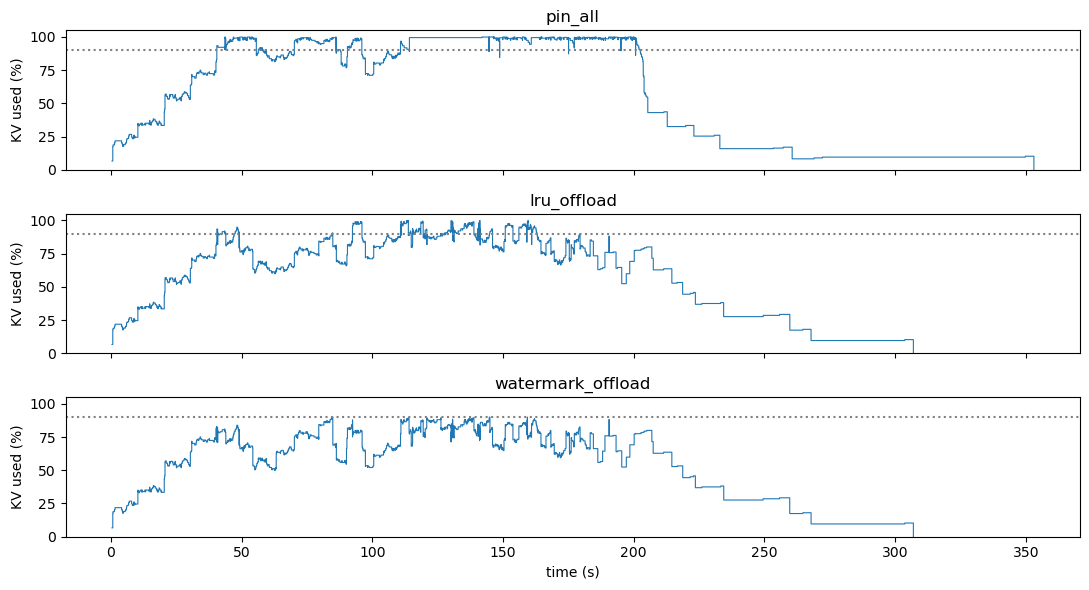

In [7]:
def occ(policy, cfg='week7_180s_stress02', run='w2_s4_seed1'):
    o = pd.read_csv(f'results/week10_{cfg}/runs/{run}__{policy}/occupancy.csv')
    return o.time_ms / 1000, o.used_blocks / o.total_blocks * 100

fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, p in zip(axes, ['pin_all', 'lru_offload', 'watermark_offload']):
    t, y = occ(p)
    ax.step(t, y, where='post', lw=0.8)
    ax.axhline(90, color='gray', ls=':')
    ax.set(ylim=(0, 105), ylabel='KV used (%)', title=p)
axes[-1].set_xlabel('time (s)')
plt.tight_layout()

## 7. 실패한 seed 의 분해

Watermark 가 떨어진 seed 는 모두 **TTFT 상대 기준** 하나에서 떨어졌다. 같은 정책 W0 의 P95 가 낮아(0.1 ~ 0.2 s) 3배 기준이 엄격하게 작동한 경우이며, 절대 P95 는 같은 run 의 Evict 보다 짧거나 같다.

In [8]:
fails = []
for name, (_, _, slo) in data.items():
    w = slo[(slo.policy == 'watermark_offload') & (~slo.all_pass)].copy()
    w.insert(0, '설정', name)
    fails.append(w[['설정', 'load', 'seed', 'w0_p95_ttft_ms', 'normal_p95_ttft_ms', 'ttft_ratio_vs_policy_w0',
                    'normal_reject_rate_pct', 'peak_kv_occupancy_pct', 'ttft_pass', 'reject_pass', 'occupancy_pass']])
display(pd.concat(fails, ignore_index=True).round(2))

,설정,load,seed,w0_p95_ttft_ms,normal_p95_ttft_ms,ttft_ratio_vs_policy_w0,normal_reject_rate_pct,peak_kv_occupancy_pct,ttft_pass,reject_pass,occupancy_pass
0,60s·0.2,burst_2x,0,194.06,613.31,3.16,0.0,89.06,False,True,True
1,60s·0.2,both_2x,0,194.06,613.31,3.16,0.0,89.53,False,True,True
2,60s·0.2,burst_4x,0,194.06,613.31,3.16,0.0,89.96,False,True,True
3,60s·0.2,both_4x,0,194.06,613.31,3.16,0.0,89.44,False,True,True
4,180s·0.2,both_4x,0,108.37,327.85,3.03,0.0,89.79,False,True,True
5,180s·0.3,burst_2x,0,116.66,537.23,4.60,0.0,90.00,False,True,True
6,180s·0.3,both_2x,0,116.66,493.05,4.23,0.0,89.91,False,True,True
7,180s·0.3,burst_4x,0,116.66,526.98,4.52,0.0,90.00,False,True,True
8,180s·0.3,both_4x,0,116.66,519.52,4.45,0.0,90.00,False,True,True


## 8. 검증

### 8-1. 상한 불변식

새 정책 두 개의 모든 run 에서 사용 블록이 `floor(0.9 × 전체)` 를 넘은 순간이 있는지 확인한다.

In [9]:
violations, checked = 0, 0
for cfg in SETTINGS.values():
    for run in Path(f'results/week10_{cfg}/runs').iterdir():
        if run.name.split('__')[1] not in ('watermark_offload', 'pin_all_capped'):
            continue
        o = pd.read_csv(run / 'occupancy.csv'); checked += 1
        violations += int(o.used_blocks.max() > math.floor(o.total_blocks.iloc[0] * 0.9))
print(f'{checked} runs checked, {violations} violations')

270 runs checked, 0 violations


### 8-2. 처음 보는 seed (5 ~ 14)

계획 · 결과에 쓰지 않은 seed 10개로 같은 매트릭스를 다시 돌린다(설정 · 상한 변경 없음).

In [10]:
holdout = {name: ensure(cfg, f'results/week10_holdout_{cfg}', seeds=tuple(range(5, 15)), keep_events=False) for name, cfg in SETTINGS.items()}
for name, (_, comp, _) in holdout.items():
    print(f'=== {name} (seed 10개 중 통과 수)')
    display(pass_table(comp, n=10))

=== 60s·0.2 (seed 10개 중 통과 수)


load,w0_1x,base_2x,burst_2x,wait_2x,both_2x,base_4x,burst_4x,wait_4x,both_4x
Pin-All,8,4,3,3,1,1,0,1,0
Evict/Recompute,8,9,10,10,10,10,10,10,10
Fixed TTL,8,4,7,8,9,7,6,9,9
LRU Offload,8,4,3,3,1,1,0,1,0
Duration-Aware,8,7,3,4,3,6,1,3,0
Watermark (제안),10,10,8,10,8,10,8,10,8
Pin-All+상한 (대조),10,8,5,3,1,2,0,2,0


=== 180s·0.2 (seed 10개 중 통과 수)


load,w0_1x,base_2x,burst_2x,wait_2x,both_2x,base_4x,burst_4x,wait_4x,both_4x
Pin-All,2,0,0,0,0,0,0,0,0
Evict/Recompute,6,5,6,7,7,10,8,9,9
Fixed TTL,3,0,0,2,4,1,1,3,1
LRU Offload,2,0,0,0,0,0,0,0,0
Duration-Aware,8,2,0,0,0,0,0,0,0
Watermark (제안),10,10,10,10,10,10,10,10,10
Pin-All+상한 (대조),9,1,1,0,0,0,0,0,0


=== 180s·0.3 (seed 10개 중 통과 수)


load,w0_1x,base_2x,burst_2x,wait_2x,both_2x,base_4x,burst_4x,wait_4x,both_4x
Pin-All,1,0,0,0,0,0,0,0,0
Evict/Recompute,1,1,0,0,1,0,0,2,0
Fixed TTL,1,0,0,0,0,0,0,0,0
LRU Offload,1,0,0,0,0,0,0,0,0
Duration-Aware,1,0,0,0,0,0,0,0,0
Watermark (제안),10,10,8,10,9,10,7,10,9
Pin-All+상한 (대조),3,1,0,0,0,0,0,0,0


## 9. 비용 민감도: 옮기는 비용이 비싸지면

180s · 0.2, seed 0 ~ 14, PCIe 12 · 6 · 3 · 1.5 GB/s × CPU 풀 64 · 4 · 2 · 1 GiB. 기준 정책(Evict · Fixed TTL · Pin-All)은 PCIe · CPU 를 쓰지 않으므로 한 번만 돌린다.

In [11]:
if not Path('results/cost_sensitivity/sensitivity.csv').exists():
    run_cost_sensitivity('configs/week7_180s_stress02.json', 'configs/system_1080ti_llama3b.json',
                         'configs/policies_week7.json', 'results/cost_sensitivity')
if not Path('results/cost_baseline/comparison.csv').exists():
    run_w2_factorial('configs/week7_180s_stress02.json', 'configs/system_1080ti_llama3b.json', 'configs/policies_week7.json',
                     'results/cost_baseline', seeds=tuple(range(15)), policies=('evict_recompute', 'fixed_ttl', 'pin_all'), keep_events=False)
sens = pd.read_csv('results/cost_sensitivity/sensitivity.csv')
base = pd.read_csv('results/cost_baseline/comparison.csv')
sens['passed'] = sens.all_slo_pass_rate_pct / 100 * 15
base['passed'] = base.all_slo_pass_rate_pct / 100 * 15
ev = base[base.policy == 'evict_recompute']
E_pass, E_ttft = ev.passed.sum(), ev.normal_p95_ttft_ms_mean.mean()
w = sens[sens.policy == 'watermark_offload'].groupby(['pcie_gbps', 'cpu_gib']).agg(
    passed=('passed', 'sum'), ttft=('normal_p95_ttft_ms_mean', 'mean'), recompute_k=('recomputed_tokens_mean', lambda x: x.mean() / 1000))
w['Evict 대비'] = ['유지' if p >= E_pass and t <= E_ttft else '역전' for p, t in zip(w.passed, w.ttft)]
print(f'Evict: 통과 {E_pass:.0f}/135, 평균 TTFT {E_ttft:.0f} ms')
display(w.sort_index(ascending=False).round(1))

Evict: 통과 98/135, 평균 TTFT 722 ms


passed   ttft  recompute_k Evict 대비
pcie_gbps cpu_gib                                     
12.0      64.0      134.0  271.8          0.0       유지
          4.0       134.0  276.8          4.4       유지
          2.0       132.0  317.1         26.4       유지
          1.0       131.0  369.4         60.2       유지
6.0       64.0      134.0  276.6          0.0       유지
          4.0       134.0  282.4          4.8       유지
          2.0       131.0  326.5         28.7       유지
          1.0       130.0  377.2         62.7       유지
3.0       64.0      134.0  292.7          0.0       유지
          4.0       134.0  300.6          6.1       유지
          2.0       132.0  340.6         31.8       유지
          1.0       130.0  391.7         65.4       유지
1.5       64.0      134.0  342.7          0.0       유지
          4.0       134.0  347.0          8.0       유지
          2.0       132.0  372.9         37.1       유지
          1.0       129.0  406.0         69.4       유지

### 비용이 쌓이는 자리

In [12]:
def where(path, policy):
    s = pd.read_csv(path); s = s[s.policy == policy]
    return pd.Series({'normal P95 TTFT (ms)': s.normal_p95_ttft_ms.mean(), 'prefill 사용률 (%)': s.prefill_busy_pct.mean(),
                      'PCIe 사용률 (%)': s.pcie_busy_pct.mean()})
display(pd.DataFrame({
    'Evict/Recompute': where('results/cost_baseline/summary.csv', 'evict_recompute'),
    'Watermark 12 GB/s · 64 GiB': where('results/cost_sensitivity/pcie12_cpu64/summary.csv', 'watermark_offload'),
    'Watermark 1.5 GB/s · 64 GiB': where('results/cost_sensitivity/pcie1.5_cpu64/summary.csv', 'watermark_offload'),
    'Watermark 1.5 GB/s · 1 GiB': where('results/cost_sensitivity/pcie1.5_cpu1/summary.csv', 'watermark_offload'),
}).T.round(1))

,normal P95 TTFT (ms),prefill 사용률 (%),PCIe 사용률 (%)
Evict/Recompute,722.1,30.3,0.0
Watermark 12 GB/s · 64 GiB,271.8,12.0,0.8
Watermark 1.5 GB/s · 64 GiB,342.7,11.9,7.6
Watermark 1.5 GB/s · 1 GiB,406.0,15.2,2.9


재계산은 일반 요청과 공유하는 prefill 을 써서 비용이 **다른 사용자의 TTFT** 로 넘어가고, offload 는 별도 PCIe 를 써서 비용이 세션 안에 머문다. 그래서 PCIe 를 8배 느리게, CPU 풀을 64배 작게 해도 역전이 없다.

## 10. 결론과 해석 범위

| 단계 | 결과 |
|---|---|
| 원인 | 기존 정책은 입장 시점을 제어하지 않아 최고 점유율을 지킬 수 없다 |
| 제안 | 입장 상한 + 오래 기다린 세션 offload: Evict 와 같은 SLO 를 재계산 없이, TTFT 절반 이하로 |
| 대조 | 상한만 두면 무너진다 → 회수가 필요하다 |
| 검증 | 상한 위반 0, 처음 보는 seed 에서도 유지 |
| 민감도 | PCIe · CPU 를 크게 낮춰도 역전 없음. 비용이 누구에게 가는지가 다르기 때문 |

- 최고 점유율 ≤ 90 % 는 상한의 정의상 보장되므로, 이 결과가 보인 것은 **90 % 여유를 강제할 때의 비용(지연 · 거절 · 전송)** 이다.
- 시뮬레이터는 prefill 을 한 번에 하나씩 처리하고(FIFO) PCIe 와 계산이 경합하지 않는다고 가정한다. 실제 서빙 엔진의 배치 prefill 에서는 Evict 의 불리함이 작아질 수 있다.
- 상한 값(0.8 · 0.85 · 0.95)은 별도 실험으로 기록한다. 시스템 연동은 구현하지 않았으며 [전망](../docs/system_outlook.md) 으로만 정리했다.